# 1. Raw Data Extraction and Overview

**Goal:** load the untouched Kaggle dataset and inspect its structure before any cleaning or model work.

**Order:** setup → load → structure → schema → summary → class balance → time/amount → data quality → report → findings.

## 1.1 Project setup

**Purpose:** locate the project and load shared paths.

**Process:** detect Google Colab or a local Python environment, then import `src/config.py`.

**Output:** confirmed project, raw-data, and report paths.

In [1]:
import os
import sys
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive/card-fraud-triage')
    IN_COLAB = True
except ImportError:
    PROJECT_ROOT = Path.cwd().resolve()
    if not (PROJECT_ROOT / 'src/config.py').is_file():
        PROJECT_ROOT = PROJECT_ROOT.parent
    IN_COLAB = False

if not (PROJECT_ROOT / 'src/config.py').is_file():
    raise FileNotFoundError('Could not locate src/config.py. Open the project root or place the project in MyDrive/card-fraud-triage.')

sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import ARTIFACTS, RAW_PATH, SEED

random.seed(SEED)
np.random.seed(SEED)
plt.style.use('seaborn-v0_8-whitegrid')

print('Environment:', 'Google Colab' if IN_COLAB else 'Local')
print('Project root:', PROJECT_ROOT)
print('Raw data:', RAW_PATH)

Environment: Local
Project root: /Users/yuvrajchandravansi/Desktop/card-fraud-triage
Raw data: /Users/yuvrajchandravansi/Desktop/card-fraud-triage/data/raw/creditcard.csv


## 1.2 Load the raw dataset

**Purpose:** read the source file exactly as provided.

**Process:** use `pandas.read_csv` on `RAW_PATH`. No filtering or modification occurs here.

**Output:** a raw dataframe and its loading status.

In [2]:
if not RAW_PATH.is_file():
    raise FileNotFoundError('Raw dataset missing: {}'.format(RAW_PATH))

df = pd.read_csv(RAW_PATH)
print('Loaded raw data:', df.shape[0], 'rows x', df.shape[1], 'columns')

Loaded raw data: 284807 rows x 31 columns


## 1.3 Inspect size, sample, types, and memory

**Purpose:** understand the shape and representation of the data.

**Process:** display the first rows, schema types, and memory footprint.

**Output:** a compact structural view of all 31 columns.

In [3]:
print('Shape:', df.shape)
display(df.head())

structure = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'non_null': df.notna().sum(),
    'memory_bytes': df.memory_usage(deep=True).drop('Index'),
})
display(structure)
print('Total memory: {:.2f} MiB'.format(structure['memory_bytes'].sum() / (1024 ** 2)))

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


,dtype,non_null,memory_bytes
Time,float64,284807,2278456
V1,float64,284807,2278456
V2,float64,284807,2278456
V3,float64,284807,2278456
V4,float64,284807,2278456
V5,float64,284807,2278456
V6,float64,284807,2278456
V7,float64,284807,2278456
V8,float64,284807,2278456
V9,float64,284807,2278456


Total memory: 67.36 MiB


## 1.4 Validate the expected schema

**Purpose:** confirm that the raw file contains the fraud-detection columns required later.

**Process:** check for `Time`, `V1`–`V28`, `Amount`, and `Class`, and verify that every required column is numeric.

**Output:** a pass/fail table. Missing or non-numeric fields stop the notebook.

In [4]:
required_columns = ['Time'] + ['V{}'.format(i) for i in range(1, 29)] + ['Amount', 'Class']
missing_columns = [column for column in required_columns if column not in df.columns]
non_numeric = [column for column in required_columns if column in df.columns and not pd.api.types.is_numeric_dtype(df[column])]

schema = pd.DataFrame([
    ('Required columns present', not missing_columns, 'Missing: {}'.format(missing_columns)),
    ('Required columns numeric', not non_numeric, 'Non-numeric: {}'.format(non_numeric)),
], columns=['check', 'passed', 'details'])
display(schema)

if not schema['passed'].all():
    raise ValueError('Schema validation failed.')
print('Schema valid: {} required columns present.'.format(len(required_columns)))

,check,passed,details
0,Required columns present,True,Missing: []
1,Required columns numeric,True,Non-numeric: []


Schema valid: 31 required columns present.


## 1.5 Review key descriptive statistics

**Purpose:** summarize elapsed time, transaction amount, and target labels.

**Process:** apply `describe()` to `Time`, `Amount`, and `Class` only.

**Output:** count, mean, spread, quartiles, minimum, and maximum.

In [5]:
key_summary = df[['Time', 'Amount', 'Class']].describe().T
display(key_summary)

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16
Class,284807.0,0.001727,0.041527,0.0,0.0,0.0,0.000,1.00


## 1.6 Examine class imbalance

**Purpose:** quantify fraud prevalence.

**Process:** count both classes and draw a labeled bar chart.

**Output:** counts, fraud percentage, and a visible imbalance comparison.

,transactions,percentage
Legitimate (0),NaN,NaN
Fraud (1),NaN,NaN


Fraud prevalence: 0.1727%


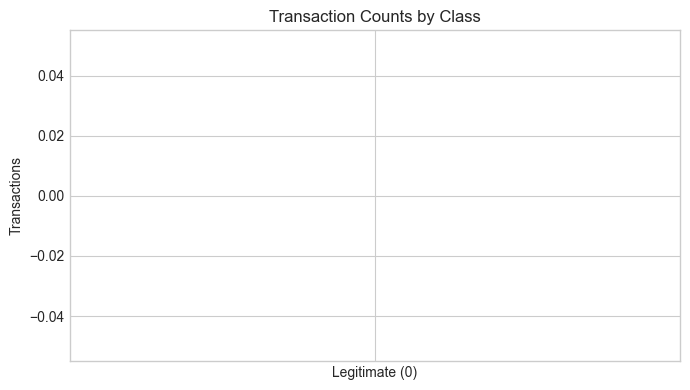

In [6]:
class_counts = df['Class'].value_counts().reindex([0, 1], fill_value=0)
fraud_count = int(class_counts.loc[1])
fraud_rate = fraud_count / len(df)

class_table = pd.DataFrame({
    'transactions': class_counts,
    'percentage': class_counts / len(df) * 100,
}, index=['Legitimate (0)', 'Fraud (1)'])
display(class_table)
print('Fraud prevalence: {:.4f}%'.format(fraud_rate * 100))

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(class_table.index, class_table['transactions'], color=['steelblue', 'tomato'])
ax.set_title('Transaction Counts by Class')
ax.set_ylabel('Transactions')
ax.bar_label(bars, labels=['{:,.0f}'.format(value) for value in class_table['transactions']], padding=3)
plt.tight_layout()
plt.show()

## 1.7 Inspect elapsed time

**Purpose:** determine the temporal span represented by the dataset.

**Process:** convert elapsed seconds to hours and report minimum and maximum values.

**Output:** time coverage in seconds and hours.

In [7]:
time_min = float(df['Time'].min())
time_max = float(df['Time'].max())
print('Time range: {:,.0f}–{:,.0f} seconds'.format(time_min, time_max))
print('Time range: {:.2f}–{:.2f} hours'.format(time_min / 3600, time_max / 3600))

Time range: 0–172,792 seconds
Time range: 0.00–48.00 hours


## 1.8 Inspect transaction amounts

**Purpose:** understand the raw amount distribution, especially heavy-tailed values.

**Process:** plot a standard histogram and a log-scaled histogram.

**Output:** two separate views of the same distribution without changing the data.

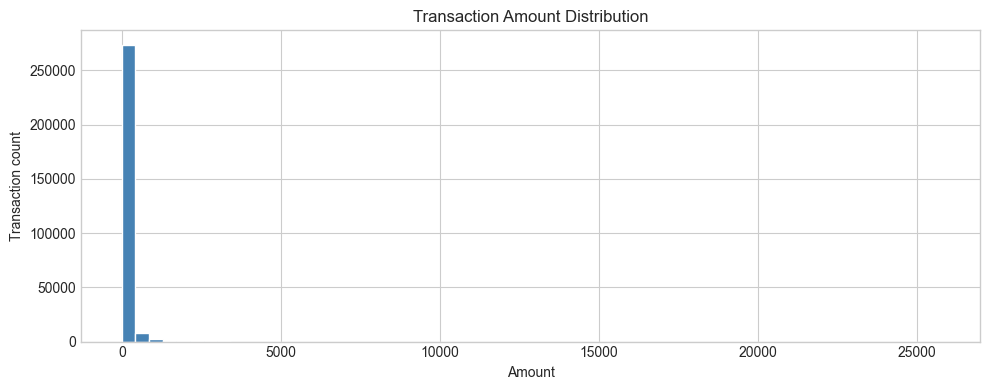

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(df['Amount'], bins=60, color='steelblue', edgecolor='white')
ax.set_title('Transaction Amount Distribution')
ax.set_xlabel('Amount')
ax.set_ylabel('Transaction count')
plt.tight_layout()
plt.show()

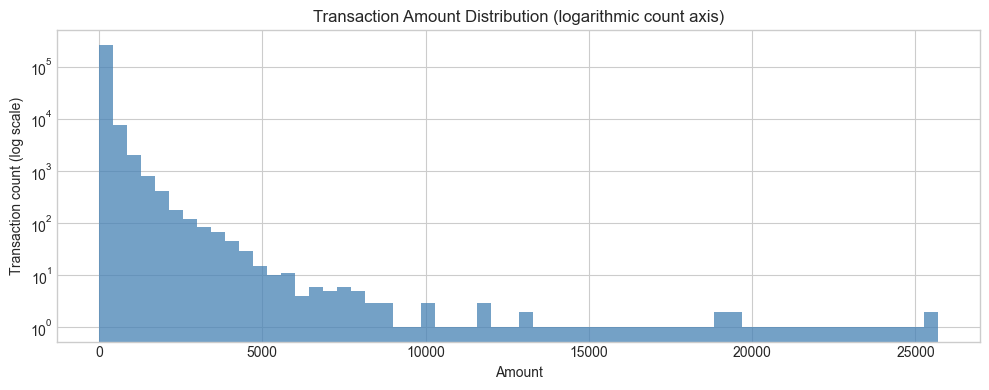

In [9]:
amount_counts, amount_edges = np.histogram(df['Amount'], bins=60)
positive_counts = amount_counts + 1

fig, ax = plt.subplots(figsize=(10, 4))
ax.stairs(positive_counts, amount_edges, fill=True, color='steelblue', alpha=0.75)
ax.set_yscale('log')
ax.set_title('Transaction Amount Distribution (logarithmic count axis)')
ax.set_xlabel('Amount')
ax.set_ylabel('Transaction count (log scale)')
plt.tight_layout()
plt.show()

## 1.9 Check data quality without modifying rows

**Purpose:** record missing values and exact duplicate rows.

**Process:** count both measures. The raw file is only inspected, not filtered or corrected.

**Output:** missing-value counts, total missing cells, and duplicate count.

In [10]:
missing_by_column = df.isna().sum().astype(int)
duplicate_count = int(df.duplicated().sum())

quality = pd.DataFrame({
    'missing_values': missing_by_column,
}, index=missing_by_column.index)
display(quality[quality['missing_values'] > 0])
print('Total missing cells:', int(missing_by_column.sum()))
print('Exact duplicate rows:', duplicate_count)

,missing_values


Total missing cells: 0
Exact duplicate rows: 1081


## 1.10 Save the extraction audit report

**Purpose:** preserve a small machine-readable summary for later notebooks and reproducibility.

**Process:** write shape, fraud prevalence, missing values, duplicates, and time range to JSON.

**Output:** `artifacts/extraction_report.json`.

In [11]:
extraction_report = {
    'shape': [int(df.shape[0]), int(df.shape[1])],
    'fraud_count': fraud_count,
    'fraud_rate': fraud_rate,
    'fraud_percentage': fraud_rate * 100,
    'missing': {column: int(count) for column, count in missing_by_column.items()},
    'duplicates': duplicate_count,
    'time_range': {
        'seconds': {'min': time_min, 'max': time_max},
        'hours': {'min': time_min / 3600, 'max': time_max / 3600},
    },
}

report_path = Path(ARTIFACTS) / 'extraction_report.json'
report_path.write_text(json.dumps(extraction_report, indent=2) + chr(10), encoding='utf-8')
print('Saved extraction report:', report_path)

Saved extraction report: /Users/yuvrajchandravansi/Desktop/card-fraud-triage/artifacts/extraction_report.json


## 1.11 Key findings

- The raw file contains **284,807 transactions** and **31 columns**.
- Every required field is numeric and the expected schema is present.
- Fraud is highly imbalanced: only a small fraction of transactions are fraud.
- `Time` spans approximately two days.
- `Amount` is strongly right-skewed and has a heavy tail.
- The raw values are not modified in this notebook.
- Missing values and duplicate rows are recorded for the cleaning stage.

The next notebook applies the agreed cleaning policy and writes `data/processed/creditcard_clean.csv`.